In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn import datasets
from sklearn.model_selection import train_test_split

In [2]:
df=pd.read_csv('titanic_data_updated.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,no,second,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,yes,first,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,no,third,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,yes,first,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## Feature Engineering starter

In [3]:
df.drop(['PassengerId','Name','Ticket'],axis=1,inplace=True)


In [4]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,no,third,male,22.0,1,0,7.2500,NaN,S
1,yes,first,female,38.0,1,0,71.2833,C85,C
2,yes,third,female,26.0,0,0,7.9250,NaN,S
3,yes,first,female,35.0,1,0,53.1000,C123,S
4,no,third,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...
886,no,second,male,27.0,0,0,13.0000,NaN,S
887,yes,first,female,19.0,0,0,30.0000,B42,S
888,no,third,female,NaN,1,2,23.4500,NaN,S
889,yes,first,male,26.0,0,0,30.0000,C148,C


In [ ]:
# df.drop(['Cabin'],axis=1,inplace=True)


In [72]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,no,third,male,22.0,1,0,7.2500,NaN,S
1,yes,first,female,38.0,1,0,71.2833,C85,C
2,yes,third,female,26.0,0,0,7.9250,NaN,S
3,yes,first,female,35.0,1,0,53.1000,C123,S
4,no,third,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...
886,no,second,male,27.0,0,0,13.0000,NaN,S
887,yes,first,female,19.0,0,0,30.0000,B42,S
888,no,third,female,NaN,1,2,23.4500,NaN,S
889,yes,first,male,26.0,0,0,30.0000,C148,C


In [73]:
x=df.drop(['Survived'],axis=1)
x

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,third,male,22.0,1,0,7.2500,NaN,S
1,first,female,38.0,1,0,71.2833,C85,C
2,third,female,26.0,0,0,7.9250,NaN,S
3,first,female,35.0,1,0,53.1000,C123,S
4,third,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...
886,second,male,27.0,0,0,13.0000,NaN,S
887,first,female,19.0,0,0,30.0000,B42,S
888,third,female,NaN,1,2,23.4500,NaN,S
889,first,male,26.0,0,0,30.0000,C148,C


In [74]:
y=df['Survived']
y

0       no
1      yes
2      yes
3      yes
4       no
      ... 
886     no
887    yes
888     no
889    yes
890     no
Name: Survived, Length: 891, dtype: object

In [75]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [76]:
x_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
331,first,male,45.5,0,0,28.5000,C124,S
733,second,male,23.0,0,0,13.0000,NaN,S
382,third,male,32.0,0,0,7.9250,NaN,S
704,third,male,26.0,1,0,7.8542,NaN,S
813,third,female,6.0,4,2,31.2750,NaN,S
...,...,...,...,...,...,...,...,...
106,third,female,21.0,0,0,7.6500,NaN,S
270,first,male,NaN,0,0,31.0000,NaN,S
860,third,male,41.0,2,0,14.1083,NaN,S
435,first,female,14.0,1,2,120.0000,B96 B98,S


In [77]:
y_train

331     no
733     no
382     no
704     no
813     no
      ... 
106    yes
270     no
860     no
435    yes
102     no
Name: Survived, Length: 712, dtype: object

# Imputing missing value

In [13]:
df.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [14]:
x_train.isnull().sum()

Pclass        0
Sex           0
Age         140
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [15]:
y_train.isnull().sum()

np.int64(0)

In [16]:
age_mean=x_train['Age'].mean()
age_mean

np.float64(29.498846153846156)

In [17]:
x_train['Age_imputer_mean']=x_train['Age'].fillna(age_mean)
x_test['Age_imputer_mean']=x_test['Age'].fillna(age_mean)

In [18]:
# x_train
x_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Age_imputer_mean
709,third,male,NaN,1,1,15.2458,C,29.498846
439,second,male,31.0,0,0,10.5000,S,31.000000
840,third,male,20.0,0,0,7.9250,S,20.000000
720,second,female,6.0,0,1,33.0000,S,6.000000
39,third,female,14.0,1,0,11.2417,C,14.000000
...,...,...,...,...,...,...,...,...
433,third,male,17.0,0,0,7.1250,S,17.000000
773,third,male,NaN,0,0,7.2250,C,29.498846
25,third,female,38.0,1,5,31.3875,S,38.000000
84,second,female,17.0,0,0,10.5000,S,17.000000


In [19]:
age_median=x_train['Age'].median()
age_median

28.0

In [20]:
x_train['Age_imputer_median']=x_train['Age'].fillna(age_median)
x_test['Age_imputer_median']=x_test['Age'].fillna(age_median)

In [21]:
x_train
x_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Age_imputer_mean,Age_imputer_median
709,third,male,NaN,1,1,15.2458,C,29.498846,28.0
439,second,male,31.0,0,0,10.5000,S,31.000000,31.0
840,third,male,20.0,0,0,7.9250,S,20.000000,20.0
720,second,female,6.0,0,1,33.0000,S,6.000000,6.0
39,third,female,14.0,1,0,11.2417,C,14.000000,14.0
...,...,...,...,...,...,...,...,...,...
433,third,male,17.0,0,0,7.1250,S,17.000000,17.0
773,third,male,NaN,0,0,7.2250,C,29.498846,28.0
25,third,female,38.0,1,5,31.3875,S,38.000000,38.0
84,second,female,17.0,0,0,10.5000,S,17.000000,17.0


<Axes: xlabel='Age_imputer_mean', ylabel='Density'>

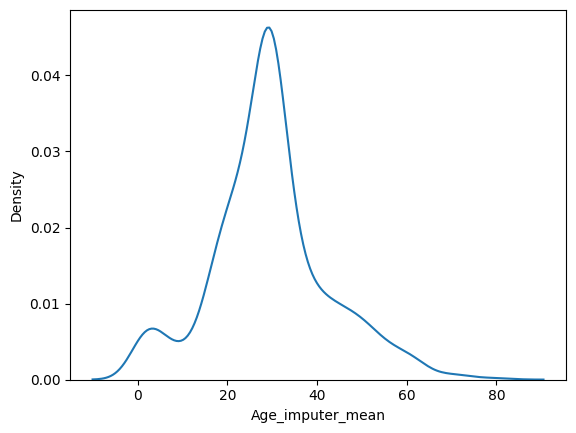

In [22]:
sns.kdeplot(data=x_train,x='Age_imputer_mean')

<Axes: xlabel='Age_imputer_median', ylabel='Density'>

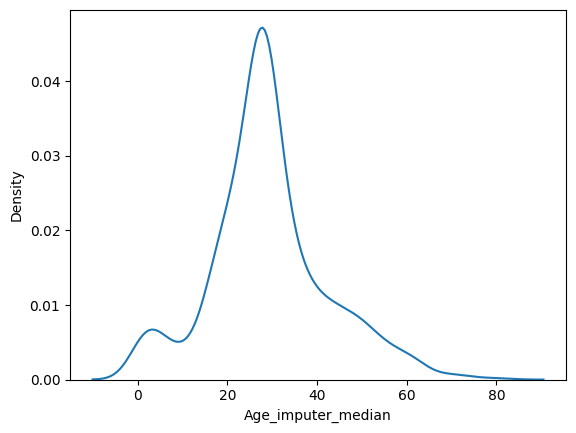

In [23]:
sns.kdeplot(data=x_train,x='Age_imputer_median')

# Simple Imputer

In [78]:
from sklearn.impute import SimpleImputer
age_imputer=SimpleImputer(missing_values=np.nan,strategy='mean')
age_imputer.fit(x_train[['Age']])
x_train['Age']=age_imputer.transform(x_train[['Age']])

x_train.isnull().sum()

Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Cabin       553
Embarked      2
dtype: int64

In [79]:
x_train.drop(['Age_imputer_mean','Age_imputer_median'],axis=1)

KeyError: "['Age_imputer_mean', 'Age_imputer_median'] not found in axis"

In [31]:
x_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Age_imputer_mean,Age_imputer_median
331,first,male,45.500000,0,0,28.5000,S,45.500000,45.5
733,second,male,23.000000,0,0,13.0000,S,23.000000,23.0
382,third,male,32.000000,0,0,7.9250,S,32.000000,32.0
704,third,male,26.000000,1,0,7.8542,S,26.000000,26.0
813,third,female,6.000000,4,2,31.2750,S,6.000000,6.0
...,...,...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,S,21.000000,21.0
270,first,male,29.498846,0,0,31.0000,S,29.498846,28.0
860,third,male,41.000000,2,0,14.1083,S,41.000000,41.0
435,first,female,14.000000,1,2,120.0000,S,14.000000,14.0


In [80]:
# for x_test
x_test['Age']=age_imputer.transform(x_test[['Age']])
x_test.isnull().sum()
x_test.drop(['Age_imputer_mean','Age_imputer_median'],axis=1)

KeyError: "['Age_imputer_mean', 'Age_imputer_median'] not found in axis"

In [81]:
df=pd.read_csv('titanic_data_updated.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,no,second,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,yes,first,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,no,third,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,yes,first,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [82]:
df.drop(['PassengerId','Name','Ticket'],axis=1,inplace=True)


In [36]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

<Axes: xlabel='Embarked', ylabel='count'>

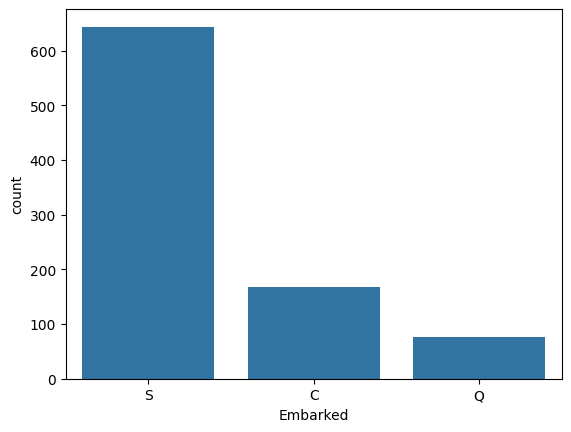

In [37]:
sns.countplot(data=df,x=df['Embarked'])

In [ ]:
embarked_imputer=SimpleImputer(missing_values=np.nan,strategy='most_frequent')
embarked_imputer.fit(df[['Embarked']])
# embarked_imputer.transform(x_train[['Embarked']])


# transform both train and test data

x_train['Embarked']=embarked_imputer.transform(x_train[['Embarked']]).ravel()
x_test['Embarked']=embarked_imputer.transform(x_test[['Embarked']]).ravel()


In [87]:
x_train.isnull().sum()
x_test.isnull().sum()

Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Cabin       134
Embarked      0
dtype: int64

<Axes: xlabel='Cabin', ylabel='count'>

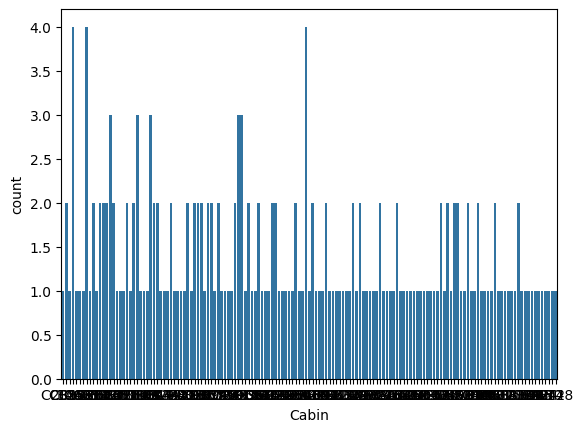

In [88]:
sns.countplot(data=df,x=df['Cabin'])

In [91]:
cabin_imputer=SimpleImputer(missing_values=np.nan,strategy='constant',fill_value='Missing',add_indicator=True)
cabin_imputer.fit(df[['Cabin']])
x_train[['Cabin','cabin_missing_indicator']]=cabin_imputer.transform(x_train[['Cabin']])
x_test[['Cabin','cabin_missing_indicator']]=cabin_imputer.transform(x_test[['Cabin']])


# cabin_imputer = SimpleImputer(missing_values=np.nan, strategy='constant', fill_value='Missing', add_indicator=True)
# cabin_imputer.fit(df[['Cabin']])

# # FIX: Use square brackets [] inside the selection to pass it as a list
# x_train[['Cabin', 'cabin_missing_indicator']] = cabin_imputer.transform(x_train[['Cabin']])
# x_test[['Cabin', 'cabin_missing_indicator']] = cabin_imputer.transform(x_test[['Cabin']])


In [93]:
#checking the null value of the x_train and x_test
x_train.isnull().sum()
x_test.isnull().sum()

Pclass                     0
Sex                        0
Age                        0
SibSp                      0
Parch                      0
Fare                       0
Cabin                      0
Embarked                   0
cabin_missing_indicator    0
dtype: int64

In [94]:
x_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,cabin_missing_indicator
331,first,male,45.500000,0,0,28.5000,C124,S,False
733,second,male,23.000000,0,0,13.0000,Missing,S,False
382,third,male,32.000000,0,0,7.9250,Missing,S,False
704,third,male,26.000000,1,0,7.8542,Missing,S,False
813,third,female,6.000000,4,2,31.2750,Missing,S,False
...,...,...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,Missing,S,False
270,first,male,29.498846,0,0,31.0000,Missing,S,False
860,third,male,41.000000,2,0,14.1083,Missing,S,False
435,first,female,14.000000,1,2,120.0000,B96 B98,S,False


<Axes: xlabel='Cabin', ylabel='count'>

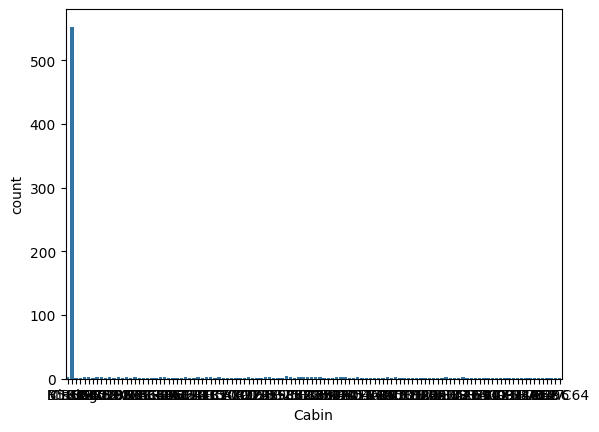

In [97]:
sns.countplot(data=x_train,x=x_train['Cabin'])